# Watch First-Order Optimizers Move

This notebook follows the visual idea of the SDS431 first-order demo:
draw contours, overlay optimizer trajectories, and compare objective values.
We put gradient descent, heavy-ball momentum, Nesterov-style momentum,
AdaGrad, RMSProp, and Adam on small two-dimensional problems where every
step can be drawn.

**Goals.** By the end you should be able to

1. translate between the notebook's momentum buffer and the slides'
   moving-average momentum, and say why their learning rates differ by a
   factor \(1-\mu\);
2. explain, from a picture, why one scalar step zig-zags on an
   ill-conditioned quadratic while per-coordinate scaling goes almost
   straight;
3. read optimizer paths on the Beale and Rosenbrock functions and connect
   what you see to each update rule, including why AdaGrad stalls;
4. compute Adam's first step by hand and explain what bias correction does;
5. tell coupled L2 regularization in Adam apart from AdamW's decoupled
   weight decay;
6. check that the hand-written update rules agree with `torch.optim`.

Run the cells in order. There is no dataset to download and no randomness:
every run is deterministic. Learning rates are chosen separately for clear,
stable paths. An equal numerical rate would not mean an equal effective step
across these algorithms. The whole notebook runs in a few seconds on a
laptop CPU.

## Heavy-ball and Nesterov are different

*Heavy-ball momentum is on the slides. Nesterov is optional: it goes beyond
the slides, and nothing later in the lecture depends on it.*

With \(g_t=\nabla f(\theta_t)\), heavy-ball uses the buffer

$$b_t=\mu b_{t-1}+g_t,\qquad
  \theta_{t+1}=\theta_t-\eta b_t.$$

For a fixed learning rate, this is equivalently

$$\theta_{t+1}
  =\theta_t-\eta g_t+\mu(\theta_t-\theta_{t-1}).$$

The last term carries forward the previous displacement, giving the
heavy-ball method its name. Nesterov's idea is to anticipate that motion
before committing to the next step. In PyTorch, the Nesterov option uses
the same buffer but takes direction

$$d_t=g_t+\mu b_t=(1+\mu)g_t+\mu^2b_{t-1}.$$

The extra current-gradient term helps the direction turn when new gradients
disagree with old momentum. This is the lookahead-inspired form used by
PyTorch; it does not request a second gradient evaluation at a lookahead
point. Muon makes the same choice before orthogonalizing a matrix update.
See the [PyTorch SGD update](https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html)
and [Muon update](https://docs.pytorch.org/docs/stable/generated/torch.optim.Muon.html).

### Matching the slides' momentum notation

The slides write momentum as a moving average,

$$m_t=\beta m_{t-1}+(1-\beta)g_t,\qquad
  \theta_{t+1}=\theta_t-\eta_{\rm slides}\,m_t,$$

while this notebook (and PyTorch's `SGD(momentum=mu)`) keeps the undamped
sum \(b_t=\mu b_{t-1}+g_t\) and steps \(\theta_{t+1}=\theta_t-\eta_{\rm nb}b_t\).
Take \(\beta=\mu\) and \(m_0=b_0=0\). If \(m_{t-1}=(1-\mu)b_{t-1}\), then

$$m_t=\mu(1-\mu)b_{t-1}+(1-\mu)g_t=(1-\mu)\bigl(\mu b_{t-1}+g_t\bigr)
     =(1-\mu)b_t,$$

so by induction \(m_t=(1-\mu)b_t\) for every \(t\). The two steps
\(\eta_{\rm slides}m_t\) and \(\eta_{\rm nb}b_t\) agree at every step exactly
when

$$\eta_{\rm nb}=(1-\mu)\,\eta_{\rm slides},
  \qquad\text{equivalently}\qquad
  \eta_{\rm slides}=\frac{\eta_{\rm nb}}{1-\mu}.$$

With \(\mu=0.9\), the notebook's heavy-ball rate \(\eta_{\rm nb}=0.0005\) on
Rosenbrock is the slides' \(\eta_{\rm slides}=0.005\). Under a constant
gradient \(g\), \(b_t\to g/(1-\mu)\), so the notebook form moves
\(\eta_{\rm nb}/(1-\mu)\) per step in steady state, ten times its nominal
rate; the slides' average \(m_t\to g\) keeps the step at
\(\eta_{\rm slides}\). The next cell checks the equivalence numerically and
draws the two momentum directions.

max |notebook path - slides path| after 200 steps: 7.115076756936123e-20


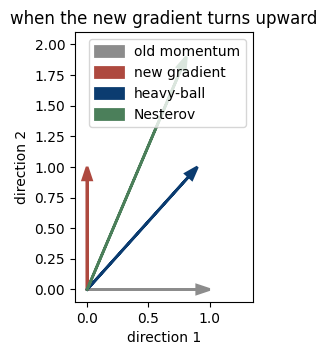

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:.4g}'.format

# Same path under the two momentum conventions (constant rate, beta = mu).
mu, eta_nb = .9, .05
eta_slides = eta_nb / (1 - mu)
grad_quad = lambda th: np.array([100 * th[0], th[1]]) / 10
th_b, th_m = np.array([1., 1.]), np.array([1., 1.])
b, m = np.zeros(2), np.zeros(2)
for t in range(200):
    b = mu * b + grad_quad(th_b)
    th_b = th_b - eta_nb * b
    m = mu * m + (1 - mu) * grad_quad(th_m)
    th_m = th_m - eta_slides * m
assert np.allclose(th_b, th_m, rtol=0, atol=1e-12)
print('max |notebook path - slides path| after 200 steps:',
      np.abs(th_b - th_m).max())

old = np.array([1., 0.])
new = np.array([0., 1.])
heavy = mu * old + new
nesterov = new + mu * heavy
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for label, vector, color in [
    ('old momentum', old, '0.55'), ('new gradient', new, '#ae493f'),
    ('heavy-ball', heavy, '#0b3c70'), ('Nesterov', nesterov, '#4b7f5a')
]:
    ax.arrow(0, 0, *vector, color=color, head_width=.07,
             length_includes_head=True, linewidth=2, label=label)
ax.set(xlim=(-.1, 1.35), ylim=(-.1, 2.1), xlabel='direction 1',
       ylabel='direction 2', title='when the new gradient turns upward')
ax.set_aspect('equal', adjustable='box')
ax.legend(loc='upper right')
plt.show()

**What the picture shows.** The old momentum points along direction 1
and the new gradient along direction 2. Heavy-ball's direction
\(\mu\cdot\text{old}+\text{new}=(0.9,1)\) still leans heavily on the old
motion. Nesterov's \((1+\mu)g_t+\mu^2b_{t-1}=(0.81,1.9)\) puts almost twice
the weight on the new gradient, so it turns faster when the landscape
bends. That same extra weight on the current gradient makes Nesterov's step
larger along steep directions, which matters in the learning-rate
experiment below.

## Read the update rules in one place

The state arrays \(m\) and \(v\) persist across steps. Heavy-ball uses
accumulated gradients; Nesterov adds the current-gradient correction.
AdaGrad sums squared gradients, RMSProp discounts them with \(\rho\), and
Adam combines discounted first and second moments (\(\beta_1\) and
\(\beta_2\), written `b1` and `b2`) with startup bias correction. The
function records the initial point and every finite subsequent iterate, and
stops at the first non-finite one.

In [2]:
METHODS = ['GD', 'Heavy-ball', 'Nesterov',
           'AdaGrad', 'RMSProp', 'Adam']

def optimize(value, gradient, start, method, lr, steps,
             mu=.9, rho=.99, b1=.9, b2=.99, eps=1e-8):
    theta = np.asarray(start, float).copy()
    m = np.zeros_like(theta)
    v = np.zeros_like(theta)
    path, values = [theta.copy()], [float(value(theta))]
    for t in range(1, steps + 1):
        g = np.asarray(gradient(theta), float)
        if method == 'GD':
            direction = g
        elif method in ('Heavy-ball', 'Nesterov'):
            m = mu * m + g
            direction = m if method == 'Heavy-ball' else g + mu * m
        elif method == 'AdaGrad':
            v += g * g
            direction = g / (np.sqrt(v) + eps)
        elif method == 'RMSProp':
            v = rho * v + (1-rho) * g * g
            direction = g / (np.sqrt(v) + eps)
        elif method == 'Adam':
            m = b1 * m + (1-b1) * g
            v = b2 * v + (1-b2) * g * g
            direction = (m/(1-b1**t)) / (np.sqrt(v/(1-b2**t)) + eps)
        else:
            raise ValueError(method)
        theta = theta - lr * direction
        current = float(value(theta))
        if not np.all(np.isfinite(theta)) or not np.isfinite(current):
            break
        path.append(theta.copy())
        values.append(current)
    return np.array(path), np.array(values)

def compare(value, gradient, start, rates, steps, methods=METHODS):
    return {method: optimize(value, gradient, start, method,
                             rates[method], steps) for method in methods}

def show_results(value, results, bounds, optimum, title,
                 levels=np.linspace(-3, 3.5, 18)):
    a = np.linspace(*bounds[0], 240)
    b = np.linspace(*bounds[1], 240)
    A, B = np.meshgrid(a, b)
    Z = np.log10(value(np.stack([A, B], axis=-1)) + 1e-5)
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    axes[0].contour(A, B, Z, levels=levels,
                    colors='0.78', linewidths=.7)
    for method, (path, values) in results.items():
        axes[0].plot(path[:,0], path[:,1], lw=1.5, label=method)
        axes[1].semilogy(np.maximum(values, 1e-12), lw=1.5, label=method)
    axes[0].scatter([optimum[0]], [optimum[1]], marker='*',
                    color='black', s=120, zorder=5)
    axes[0].set(xlabel='$\\theta_1$', ylabel='$\\theta_2$',
                xlim=bounds[0], ylim=bounds[1], title=title+' paths')
    axes[1].set(xlabel='optimizer step', ylabel='$f(\\theta_t)$',
                title=title+' objective')
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    plt.show()

def final_table(results, rates):
    return pd.DataFrame([
        {'method': name, 'learning rate': rates[name],
         'recorded steps': len(path)-1, 'final objective': values[-1],
         'final point': np.round(path[-1], 3)}
        for name, (path, values) in results.items()
    ])

## One rate per coordinate straightens the path

The slides' ill-conditioned quadratic is

$$f(\theta_1,\theta_2)=\tfrac12\bigl(100\theta_1^2+\theta_2^2\bigr),
  \qquad \nabla f(\theta)=(100\theta_1,\theta_2).$$

Gradient descent multiplies \(\theta_1\) by \(1-100\eta\) and \(\theta_2\) by
\(1-\eta\) each step, so it is stable only for \(\eta<2/100\). We use
\(\eta=0.019\), just inside that limit. Each run starts at \((1,1)\), as
far out in the steep direction as in the flat one, and takes 150 steps.

**What to look for.** GD's \(\theta_1\) factor is \(1-1.9=-0.9\): it flips
sign every step and shrinks slowly, a zig-zag across the narrow direction,
while \(\theta_2\) creeps down by a factor 0.981 per step. AdaGrad, RMSProp
and Adam divide each coordinate's gradient by that coordinate's own gradient
scale. Multiplying \(g_{t,1}\) by 100 multiplies \(\sqrt{v_{t,1}}\) by 100
too, so the factor cancels (up to \(\varepsilon\)): on this quadratic the
adaptive methods move exactly as they would on the round bowl
\(\tfrac12(\theta_1^2+\theta_2^2)\). The cell checks that claim.

,method,learning rate,recorded steps,final objective,final point
0,GD,0.019,150,0.001584,"[0.0, 0.056]"
1,AdaGrad,0.4,150,7.529e-48,"[0.0, 0.0]"
2,RMSProp,0.02,150,2.679e-21,"[0.0, 0.0]"
3,Adam,0.05,150,9.865e-06,"[0.0, 0.0]"


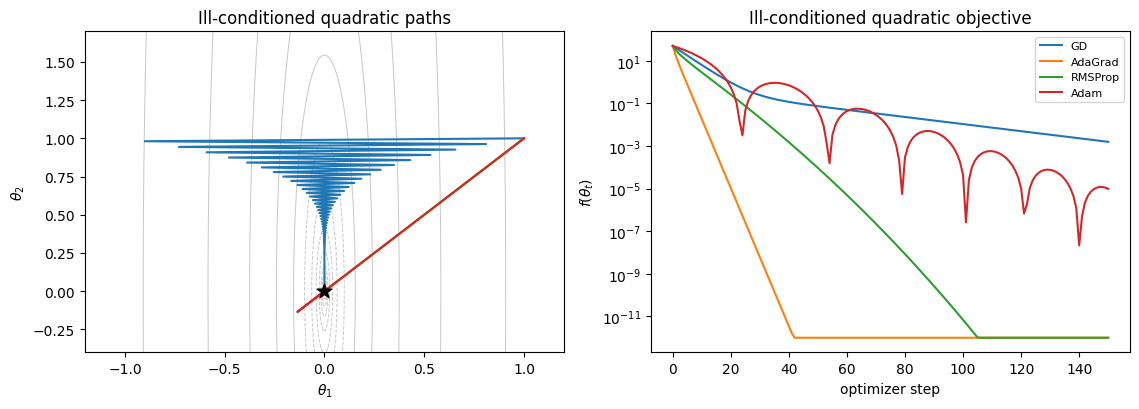

GD with eta=0.021: f after 150 steps = 1.31e+14
AdaGrad  curvature 100 vs round bowl: max gap 4.7e-09; max |theta1 - theta2| along the path 4.7e-09
RMSProp  curvature 100 vs round bowl: max gap 3.6e-08; max |theta1 - theta2| along the path 3.6e-08
Adam     curvature 100 vs round bowl: max gap 9.5e-09; max |theta1 - theta2| along the path 9.5e-09


In [3]:
def quad(theta):
    return .5 * (100 * theta[..., 0]**2 + theta[..., 1]**2)

def quad_grad(theta):
    return np.array([100 * theta[0], theta[1]])

QUAD_RATES = {'GD': .019, 'AdaGrad': .4, 'RMSProp': .02, 'Adam': .05}
QUAD_START = [1., 1.]
quad_results = compare(quad, quad_grad, QUAD_START, QUAD_RATES, 150,
                       methods=list(QUAD_RATES))
display(final_table(quad_results, QUAD_RATES))
show_results(quad, quad_results, ((-1.2, 1.2), (-.4, 1.7)), (0, 0),
             'Ill-conditioned quadratic', levels=np.linspace(-3, 2, 14))

# GD just above the stability limit 2/100 blows up along theta_1.
_, gd_unstable = optimize(quad, quad_grad, QUAD_START, 'GD', .021, 150)
print(f'GD with eta=0.021: f after 150 steps = {gd_unstable[-1]:.3g}')

# Adaptive methods ignore the factor 100: same path on the round bowl.
iso = lambda th: .5 * (th[..., 0]**2 + th[..., 1]**2)
for method in ['AdaGrad', 'RMSProp', 'Adam']:
    iso_path, _ = optimize(iso, lambda th: th.copy(), QUAD_START, method,
                           QUAD_RATES[method], 150)
    gap = np.abs(iso_path - quad_results[method][0]).max()
    off_diagonal = np.abs(np.diff(quad_results[method][0], axis=1)).max()
    assert gap < 1e-6
    print(f'{method:8s} curvature 100 vs round bowl: max gap {gap:.1e};'
          f' max |theta1 - theta2| along the path {off_diagonal:.1e}')

**Interpretation.** GD bounces across the steep \(\theta_1\) direction:
\(\theta_1\) changes sign every step and shrinks only by the factor 0.9, while
\(\theta_2\) decays by 0.981 per step and is still at 0.056 after 150 steps
(\(f\approx1.6\times10^{-3}\)). The flat direction cannot be sped up by a
larger rate: at \(\eta=0.021\), \(|1-100\eta|=1.1\) and \(f\) exceeds
\(10^{14}\) after 150 steps. The three adaptive paths lie on top of one
another along the diagonal \(\theta_1=\theta_2\) (they stay within
\(4\times10^{-8}\) of it), which is the straight line to the minimum and
exactly their path on the round bowl. AdaGrad gets below \(10^{-6}\) by step
24 and RMSProp by step 66. Adam's momentum carries it past the minimum
along the diagonal, which produces the bumps in its objective curve; it is
at \(f\approx10^{-5}\) after 150 steps. The straight line comes from a
start on the diagonal. From another start, each adaptive method follows its
round-bowl path from that start, which can bend (Try It, exercise 1).

## Beale's curved valley

$$f(x,y)=(1.5-x+xy)^2+(2.25-x+xy^2)^2+(2.625-x+xy^3)^2.$$

Its minimum is \(f(3,0.5)=0\). Each run begins at \((1,1)\). The
contours show where a method travels; the right panel shows when it makes
progress. The star marks the minimum. The learning rates were picked to
give readable paths, so read the plot as a picture of mechanisms.

,method,learning rate,recorded steps,final objective,final point
0,GD,0.01,500,0.001421,"[2.91, 0.477]"
1,Heavy-ball,0.006,500,4.873e-12,"[3.0, 0.5]"
2,Nesterov,0.004,500,6.885e-09,"[3.0, 0.5]"
3,AdaGrad,0.15,500,0.003346,"[2.866, 0.464]"
4,RMSProp,0.012,500,2.818e-05,"[2.987, 0.497]"
5,Adam,0.04,500,4.902e-14,"[3.0, 0.5]"


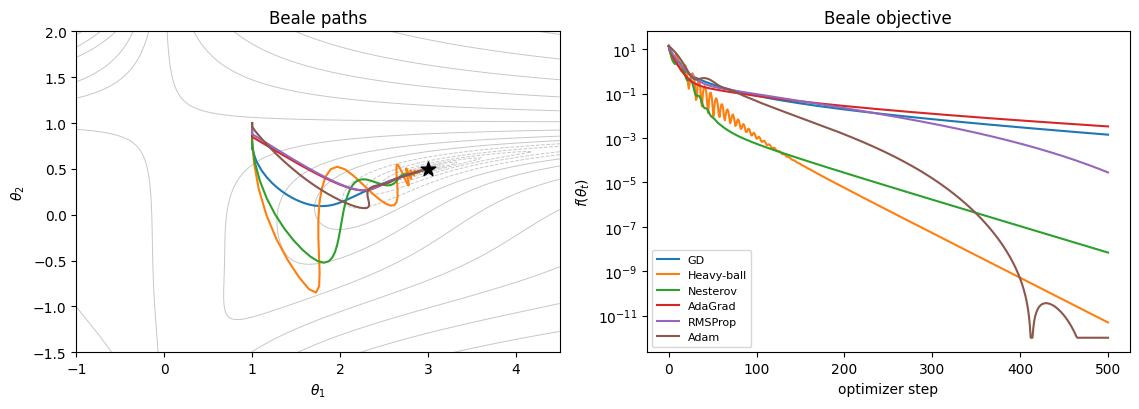

In [4]:
def beale(theta):
    x, y = theta[...,0], theta[...,1]
    return ((1.5-x+x*y)**2 + (2.25-x+x*y*y)**2
            + (2.625-x+x*y**3)**2)

def beale_grad(theta):
    x, y = theta
    r = np.array([1.5-x+x*y, 2.25-x+x*y*y, 2.625-x+x*y**3])
    return np.array([
        2*np.dot(r, [-1+y, -1+y*y, -1+y**3]),
        2*x*np.dot(r, [1, 2*y, 3*y*y])
    ])

BEALE_RATES = {'GD': .01, 'Heavy-ball': .006, 'Nesterov': .004,
               'AdaGrad': .15, 'RMSProp': .012, 'Adam': .04}
beale_results = compare(beale, beale_grad, [1.,1.], BEALE_RATES, 500)
display(final_table(beale_results, BEALE_RATES))
show_results(beale, beale_results, ((-1,4.5),(-1.5,2)),
             (3,.5), 'Beale')

**Interpretation.** Momentum is the big win on Beale. Heavy-ball
and Nesterov drop below \(10^{-2}\) by steps 51 and 48 and finish at
\(5\times10^{-12}\) and \(7\times10^{-9}\). They pay with detours: heavy-ball
swings down to \(\theta_2\approx-0.85\) and Nesterov to \(-0.52\) before
curving back to the star, and heavy-ball's objective oscillates over the
first hundred or so steps. Adam takes a smoother route and reaches the
smallest value, about \(10^{-16}\) at step 478 (the plot clips at
\(10^{-12}\)). GD, AdaGrad, and RMSProp move along the valley floor without
overshooting and are still short of \((3,0.5)\) after 500 steps: GD ends
at \(f\approx1.4\times10^{-3}\), AdaGrad at \(3.3\times10^{-3}\), RMSProp at
\(2.8\times10^{-5}\). Along this long, gently sloping floor, accumulated
velocity is what keeps a method moving.

## Rosenbrock's narrow, bent valley

$$f(x,y)=(1-x)^2+100(y-x^2)^2.$$

Its minimum is \(f(1,1)=0\). Each run begins at \((-1.5,1.5)\).
Momentum may overshoot across the narrow valley, and adaptive methods
rescale coordinates. Early progress need not predict the final result.

,method,learning rate,recorded steps,final objective,final point
0,GD,0.001,1500,0.2854,"[0.466, 0.215]"
1,Heavy-ball,0.0005,1500,0.000322,"[0.982, 0.964]"
2,Nesterov,0.0004,1500,0.001766,"[0.958, 0.918]"
3,AdaGrad,0.08,1500,3.92,"[-0.979, 0.964]"
4,RMSProp,0.004,1500,0.04019,"[0.806, 0.655]"
5,Adam,0.025,1500,0.0008722,"[0.999, 1.0]"


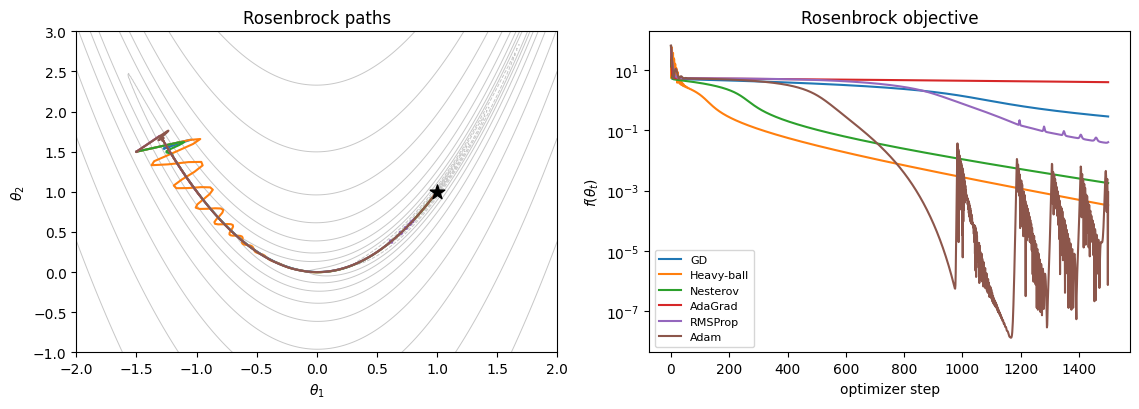

In [5]:
def rosenbrock(theta):
    x, y = theta[...,0], theta[...,1]
    return (1-x)**2 + 100*(y-x*x)**2

def rosenbrock_grad(theta):
    x, y = theta
    return np.array([-2*(1-x)-400*x*(y-x*x), 200*(y-x*x)])

ROSEN_RATES = {'GD': .001, 'Heavy-ball': .0005, 'Nesterov': .0004,
               'AdaGrad': .08, 'RMSProp': .004, 'Adam': .025}
rosen_results = compare(rosenbrock, rosenbrock_grad, [-1.5,1.5],
                        ROSEN_RATES, 1500)
display(final_table(rosen_results, ROSEN_RATES))
show_results(rosenbrock, rosen_results, ((-2,2),(-1,3)),
             (1,1), 'Rosenbrock')

**Interpretation.** Every run falls from \(f=62.5\) to about 5 within
its first dozen steps, which puts it in the curved valley; the long trip
along the valley floor then separates them. **AdaGrad stalls**: after 1500 steps it sits at
\((-0.98,0.96)\) with \(f\approx3.92\), barely past the valley entrance. This
is the AdaGrad slowdown the slides describe, and the next section shows its
cause. GD only reaches \(f\approx0.285\) at \((0.47,0.22)\), and RMSProp
reaches \(f\approx0.040\) at \((0.81,0.66)\), with small late spikes.
Heavy-ball zig-zags across the valley during its first hundred steps (the
orange path) and then glides along the floor to \(f\approx3.2\times10^{-4}\)
at \((0.98,0.96)\); Nesterov, at the smaller rate 0.0004, ends at
\(1.8\times10^{-3}\). Adam is the only method to go below \(10^{-6}\) (at
step 968), reaching \(1.3\times10^{-8}\) at step 1167, but it repeatedly
bursts back up, to values between about 0.005 and 0.04. Near the minimum its gradients
are tiny, so \(\sqrt{\widehat v_t}\) shrinks, the normalized step stays near
\(\eta\), and it overshoots. Over the last 30 steps its objective
ranges from \(7\times10^{-7}\) to \(4\times10^{-3}\), so the final
\(8.7\times10^{-4}\) at \((0.999,1.0)\) depends on where the budget happens
to end. A decaying learning rate is the usual remedy.

## Why AdaGrad stalls: effective rates over time

AdaGrad's step in coordinate \(j\) is \(\eta/(\sqrt{v_{t,j}}+\varepsilon)\)
times the gradient, where \(v_{t,j}\) is a **sum** of squared gradients;
RMSProp uses the discounted average
\(v_t=\rho v_{t-1}+(1-\rho)g_t^2\). Both states depend only on the
gradients at the visited points, so we can rebuild them from the Rosenbrock
paths above.

**What to look for.** AdaGrad's effective rate can only go down. If it
falls while the iterate is still far from \((1,1)\), the remaining budget
buys very little motion. Watch *when* it falls. RMSProp's rate tracks the
*recent* gradient size, so it can rise again once the large gradients are
in the past.

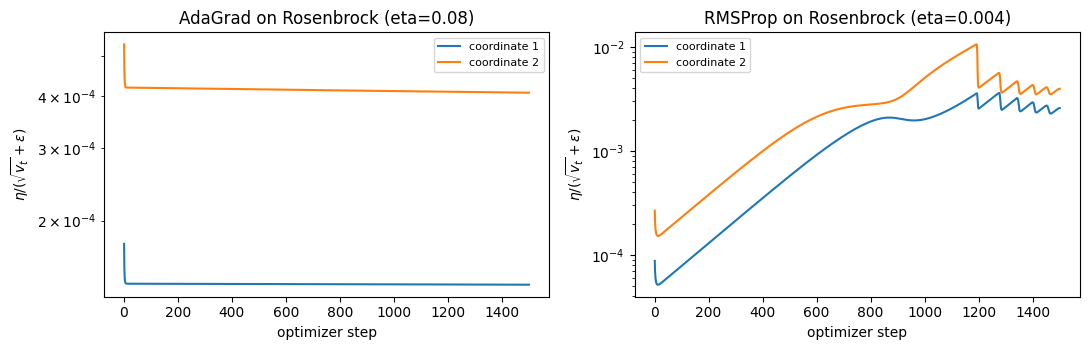

,method,step,"rate, coord 1","rate, coord 2","distance to (1,1)"
0,AdaGrad,10,0.0001409,0.0004193,2.41
1,AdaGrad,100,0.0001408,0.0004186,2.376
2,AdaGrad,1500,0.0001401,0.0004076,1.979
3,RMSProp,10,5.217e-05,0.0001535,2.44
4,RMSProp,100,7.85e-05,0.0002307,2.395
5,RMSProp,1500,0.002578,0.003956,0.3957


gradient size at the start: [-455. -150.]
share of AdaGrad's final sum v_1500 contributed by the first 10 steps: [0.988 0.945]


In [6]:
def effective_rates(path, method, lr, rho=.99, eps=1e-8):
    grads = np.array([rosenbrock_grad(p) for p in path[:-1]])
    if method == 'AdaGrad':
        v = np.cumsum(grads**2, axis=0)
    else:
        v = np.zeros_like(grads)
        acc = np.zeros(2)
        for t, g in enumerate(grads):
            acc = rho * acc + (1 - rho) * g * g
            v[t] = acc
    return lr / (np.sqrt(v) + eps)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
rate_rows = []
for ax, method in zip(axes, ['AdaGrad', 'RMSProp']):
    path, _ = rosen_results[method]
    rates = effective_rates(path, method, ROSEN_RATES[method])
    for j in range(2):
        ax.semilogy(np.arange(1, len(rates) + 1), rates[:, j],
                    label=f'coordinate {j+1}')
    ax.set(xlabel='optimizer step', ylabel='$\\eta/(\\sqrt{v_t}+\\varepsilon)$',
           title=f'{method} on Rosenbrock (eta={ROSEN_RATES[method]:g})')
    ax.legend(fontsize=8)
    for t in [10, 100, 1500]:
        rate_rows.append({'method': method, 'step': t,
                          'rate, coord 1': rates[t-1, 0],
                          'rate, coord 2': rates[t-1, 1],
                          'distance to (1,1)': np.linalg.norm(path[t] - 1)})
fig.tight_layout()
plt.show()
display(pd.DataFrame(rate_rows))
ada_g2 = np.array([rosenbrock_grad(p)
                   for p in rosen_results['AdaGrad'][0][:-1]])**2
print('gradient size at the start:', np.round(rosenbrock_grad(np.array([-1.5, 1.5])), 1))
print('share of AdaGrad\'s final sum v_1500 contributed by the first 10 steps:',
      np.round(ada_g2[:10].sum(0) / ada_g2.sum(0), 3))

**Interpretation.** AdaGrad's rate is set within its first ten
steps and barely moves afterwards: coordinate 1 goes from
\(1.409\times10^{-4}\) at step 10 to \(1.401\times10^{-4}\) at step 1500. At
the start the gradient is \((-455,-150)\), and the first ten steps contribute
98.8% and 94.5% of the final sums \(v_{1500}\). Those large early squares
never leave the sum, so for the rest of the run AdaGrad moves along the
valley floor, where gradients are much smaller, with a step sized for the
steep walls. Its distance to \((1,1)\) falls only from 2.41 to 1.98. RMSProp
starts with even smaller rates, \(5.2\times10^{-5}\) and
\(1.5\times10^{-4}\) at step 10, but it forgets: with \(\rho=0.99\) the early
squares decay by a factor of about \(e^{-1}\) every 100 steps, and its rate
grows 49-fold in coordinate 1 and 26-fold in coordinate 2, reaching
\(2.6\times10^{-3}\) and \(4.0\times10^{-3}\) at step 1500, when it is 0.40 from the minimum. The
saw-tooth drops after step 1200 are the late spikes in RMSProp's objective:
a burst of large gradients pushes \(v_t\) up and the rate down, and the rate
then recovers.

## Learning-rate sensitivity

Keep the Rosenbrock objective and starting point fixed. Vary only the
learning rate for heavy-ball and Nesterov. A large rate can overshoot or
diverge; a small one can spend the whole budget in the valley. A short
recorded path means the run diverged, since `optimize` stops recording at
the first non-finite iterate. The plot clips objective values above
\(10^3\) so that one diverging run does not hide the other curves; the
table retains its actual final value. The `np.errstate` block silences the
overflow warning from the diverging run.

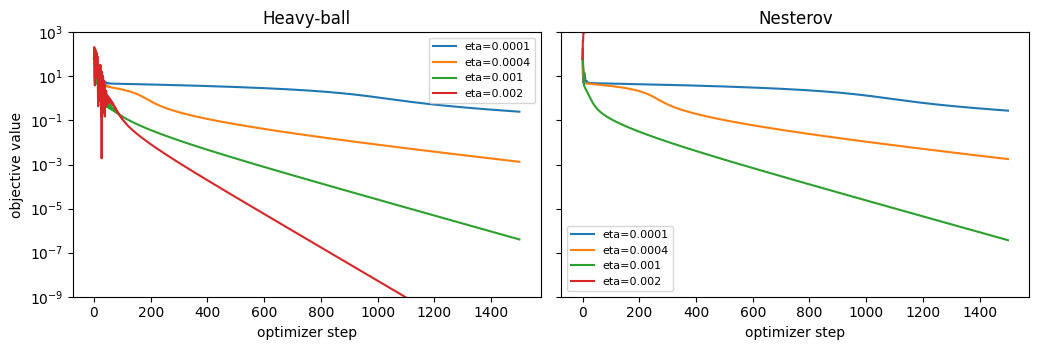

,method,learning rate,recorded steps,final objective
0,Heavy-ball,0.0001,1500,0.2503
1,Heavy-ball,0.0004,1500,0.001331
2,Heavy-ball,0.001,1500,3.971e-07
3,Heavy-ball,0.002,1500,8.797e-13
4,Nesterov,0.0001,1500,0.2792
5,Nesterov,0.0004,1500,0.001766
6,Nesterov,0.001,1500,3.68e-07
7,Nesterov,0.002,7,5.599e+131


In [7]:
rates_to_try = [.0001, .0004, .001, .002]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
rows = []
with np.errstate(over='ignore', invalid='ignore'):
    for ax, method in zip(axes, ['Heavy-ball', 'Nesterov']):
        for lr in rates_to_try:
            path, values = optimize(rosenbrock, rosenbrock_grad,
                                    [-1.5,1.5], method, lr, 1500)
            rows.append({'method': method, 'learning rate': lr,
                         'recorded steps': len(values)-1,
                         'final objective': values[-1]})
            ax.semilogy(np.clip(values, 1e-12, 1e3), label=f'eta={lr:g}')
        ax.set(xlabel='optimizer step', title=method)
        ax.legend(fontsize=8)
axes[0].set_ylabel('objective value')
axes[0].set_ylim(1e-9, 1e3)
fig.tight_layout()
plt.show()
display(pd.DataFrame(rows))

**Interpretation.** For heavy-ball the larger rates win: \(\eta=0.002\)
reaches \(9\times10^{-13}\) and \(\eta=0.001\) reaches \(4\times10^{-7}\),
while \(\eta=0.0001\) ends at 0.25, still in the valley. At \(\eta=0.002\)
heavy-ball's objective first jumps to about 213 and oscillates for a few
dozen steps before settling into the valley. Nesterov tracks heavy-ball
closely at the three smaller rates, but at \(\eta=0.002\) it **diverges in 7
steps**, with \(f\) reaching about \(10^{131}\) before it overflows. With
\(\mu=0.9\), its direction gives the current gradient weight \(1+\mu=1.9\)
where heavy-ball gives it weight 1, so the steep walls of the valley see a
larger effective step. The same lookahead that turns faster on Beale makes
Nesterov's largest stable rate smaller here.

## Adam's first step and bias correction

Adam starts from \(m_0=v_0=0\). After one gradient,
\(m_1=(1-\beta_1)g_1\) and \(v_1=(1-\beta_2)g_1^2\), and the corrections give

$$\widehat m_1=\frac{m_1}{1-\beta_1}=g_1,\qquad
  \widehat v_1=\frac{v_1}{1-\beta_2}=g_1^2,\qquad
  \theta_2-\theta_1=-\eta\frac{g_1}{|g_1|+\varepsilon}
  \approx-\eta\,\mathrm{sign}(g_1).$$

So Adam's first step has length \(\eta\) in **every** coordinate, whatever
the gradient's size. We check this for \(g_1=(2,0.5)\) with PyTorch's
defaults \(\beta_1=0.9\), \(\beta_2=0.999\), and then keep feeding the same
gradient to see how the step evolves with and without the corrections.

**What to look for.** With a constant gradient, the corrected step stays at
\(\eta\) from the first step on. Dropping only the first-moment correction
leaves \(m_t\) at \((1-\beta_1^t)g\), so early steps are tiny. Dropping
both corrections divides a small \(m_t\) by an even smaller
\(\sqrt{v_t}\), because \(1-\beta_2^t\) fills much more slowly than
\(1-\beta_1^t\).

m_hat_1 = [2.  0.5]  v_hat_1 = [4.   0.25]
first step (hand) = [-0.01 -0.01]  first step (torch) = [-0.01 -0.01]


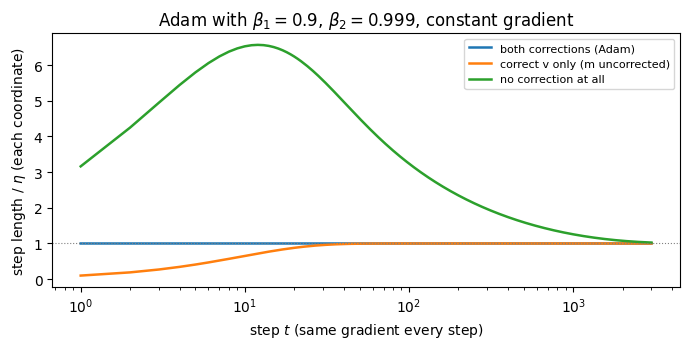

,both corrections (Adam),correct v only (m uncorrected),no correction at all
step t,,,
1,1,0.1,3.162
2,1,0.19,4.25
5,1,0.4095,5.797
10,1,0.6513,6.528
50,1,0.9948,4.504
1000,1,1,1.258
3000,1,1,1.026


In [8]:
import torch

b1, b2, eta, eps = .9, .999, .01, 1e-8
g1 = np.array([2., .5])
m1, v1 = (1 - b1) * g1, (1 - b2) * g1**2
m1_hat, v1_hat = m1 / (1 - b1), v1 / (1 - b2)
step1 = -eta * m1_hat / (np.sqrt(v1_hat) + eps)
assert np.allclose(m1_hat, g1) and np.allclose(v1_hat, g1**2)
assert np.allclose(step1, -eta * np.sign(g1), atol=1e-9)

# The same first step from torch.optim.Adam on the linear loss g1 . theta.
w = torch.zeros(2, dtype=torch.float64, requires_grad=True)
opt = torch.optim.Adam([w], lr=eta, betas=(b1, b2), eps=eps)
(torch.tensor(g1) @ w).backward()
opt.step()
assert np.allclose(w.detach().numpy(), step1, rtol=0, atol=1e-15)
print('m_hat_1 =', m1_hat, ' v_hat_1 =', v1_hat)
print('first step (hand) =', step1, ' first step (torch) =', w.detach().numpy())

T = np.arange(1, 3001)
c1, c2 = 1 - b1**T, 1 - b2**T
steps = {
    'both corrections (Adam)': np.ones_like(c1),
    'correct v only (m uncorrected)': c1,
    'no correction at all': c1 / np.sqrt(c2),
}
fig, ax = plt.subplots(figsize=(7, 3.6))
for label, s in steps.items():
    ax.semilogx(T, s, lw=1.8, label=label)
ax.axhline(1, color='0.5', lw=.8, ls=':')
ax.set(xlabel='step $t$ (same gradient every step)',
       ylabel='step length / $\\eta$ (each coordinate)',
       title='Adam with $\\beta_1=0.9$, $\\beta_2=0.999$, constant gradient')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
show_t = [1, 2, 5, 10, 50, 1000, 3000]
display(pd.DataFrame({label: s[np.array(show_t) - 1]
                      for label, s in steps.items()},
                     index=pd.Index(show_t, name='step t')))

**Interpretation.** Both corrected moments equal the first gradient
exactly, and the first step is \((-0.01,-0.01)\) from the hand calculation
and from `torch.optim.Adam`: a step of \(\eta\) in each coordinate, although
the two gradient entries differ by a factor of 4. Under a constant gradient,
corrected Adam keeps taking steps of exactly \(\eta\). Correcting only \(v\)
leaves \(m_t=(1-\beta_1^t)g\), so the first step is \(0.1\eta\) and the step
reaches \(0.99\eta\) only at step 44. Removing both corrections does the
opposite of what one might guess: since \(1-\beta_2^t\) fills much more
slowly than \(1-\beta_1^t\), the first step is \(0.1/\sqrt{0.001}\approx
3.2\eta\), the step peaks near \(6.5\eta\) around step 12, and it is still
\(1.26\eta\) at step 1000. Bias correction removes these startup
distortions, and its effect has faded once \(\beta_2^t\) is small, after a
few thousand steps for \(\beta_2=0.999\).

## Coupled L2 versus decoupled weight decay

Take one weight with **zero data loss**, so the only objective is the
penalty \(\tfrac\lambda2\theta^2\). Start at \(\theta_0=1\) and use
\(\eta=0.01\), \(\lambda=0.1\), 400 steps, as on the slide.

* `torch.optim.Adam(weight_decay=λ)` adds \(\lambda\theta_t\) to the
  gradient (coupled L2), and Adam then divides it by its own scale.
* `torch.optim.AdamW(weight_decay=λ)` shrinks \(\theta_t\mapsto(1-\eta\lambda)
  \theta_t\) and hands Adam the data gradient, which is zero here.
* `torch.optim.SGD(weight_decay=λ)` steps \(\theta_t-\eta\lambda\theta_t\),
  which is the same shrink.

**What to look for.** AdamW and SGD should land on the same curve
\((1-\eta\lambda)^t\theta_0=0.999^t\). Coupled Adam normalizes the penalty
gradient, so its steps have length about \(\eta\) regardless of how small
\(\lambda\theta_t\) is.

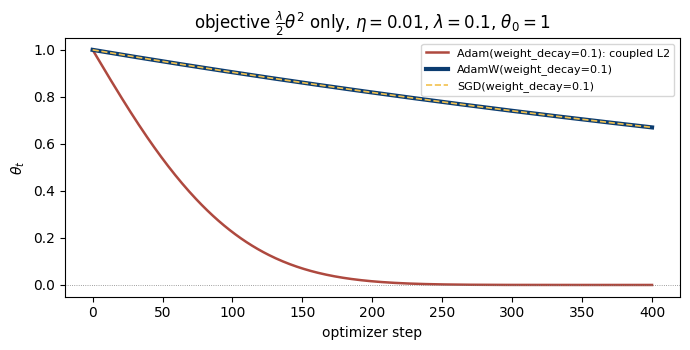

,"Adam, coupled L2",AdamW,SGD with L2
step,,,
1,0.99,0.999,0.999
10,0.9003,0.99,0.99
50,0.5368,0.9512,0.9512
100,0.2244,0.9048,0.9048
200,0.01557,0.8186,0.8186
400,-8.662e-07,0.6702,0.6702


In [9]:
def penalty_path(kind, steps=400, lr=.01, lam=.1, start=1.):
    p = torch.nn.Parameter(torch.tensor([start], dtype=torch.float64))
    if kind == 'Adam, coupled L2':
        opt = torch.optim.Adam([p], lr=lr, weight_decay=lam)
    elif kind == 'AdamW':
        opt = torch.optim.AdamW([p], lr=lr, weight_decay=lam)
    else:
        opt = torch.optim.SGD([p], lr=lr, weight_decay=lam)
    path = [p.item()]
    for _ in range(steps):
        opt.zero_grad()
        (0. * p).sum().backward()          # zero data gradient
        opt.step()
        path.append(p.item())
    return np.array(path)

decay_paths = {k: penalty_path(k) for k in
               ['Adam, coupled L2', 'AdamW', 'SGD with L2']}
exact = .999 ** np.arange(401)
assert np.allclose(decay_paths['AdamW'], exact, rtol=1e-12)
assert np.allclose(decay_paths['SGD with L2'], exact, rtol=1e-12)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(decay_paths['Adam, coupled L2'], color='#ae493f', lw=1.8,
        label='Adam(weight_decay=0.1): coupled L2')
ax.plot(decay_paths['AdamW'], color='#0b3c70', lw=3,
        label='AdamW(weight_decay=0.1)')
ax.plot(decay_paths['SGD with L2'], color='#f2c14e', lw=1.2, ls='--',
        label='SGD(weight_decay=0.1)')
ax.axhline(0, color='0.5', lw=.6, ls=':')
ax.set(xlabel='optimizer step', ylabel='$\\theta_t$',
       title='objective $\\frac{\\lambda}{2}\\theta^2$ only, '
             '$\\eta=0.01$, $\\lambda=0.1$, $\\theta_0=1$')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
display(pd.DataFrame({k: v[[1, 10, 50, 100, 200, 400]]
                      for k, v in decay_paths.items()},
                     index=pd.Index([1, 10, 50, 100, 200, 400], name='step')))

**Interpretation.** AdamW and SGD agree with \(0.999^t\) to
\(10^{-12}\), and both keep \(\theta_{400}=0.670\), the slide's 0.67. Coupled
Adam's first step goes from 1 to 0.99, ten times AdamW's first step, because
Adam divides the penalty gradient \(\lambda\theta_t\) by its own scale and
moves about \(\eta\) per step. It is at 0.224 by step 100 (the slide's 0.22),
0.016 by step 200, and \(\approx-9\times10^{-7}\) at step 400, just across
zero. So the same `weight_decay=0.1` produces very different shrinkage:
coupled L2 inside Adam is strong when the data gradient is small, and the
strength of AdamW's decay is \(\eta\lambda\) per step for every coordinate.

## Verify the implementation with PyTorch

The hand-written `optimize` is meant to be the textbook form of each rule.
Here we run the matching `torch.optim` class on Rosenbrock for 300 steps from
the same start, at the same learning rates, in float64, and compare the
paths. The settings that make the two agree:

| notebook | PyTorch |
|---|---|
| `GD` | `SGD(lr)` |
| `Heavy-ball`, buffer \(b_t=\mu b_{t-1}+g_t\) | `SGD(lr, momentum=0.9)` (default `dampening=0`) |
| `Nesterov` | `SGD(lr, momentum=0.9, nesterov=True)` |
| `AdaGrad`, \(\varepsilon=10^{-8}\) | `Adagrad(lr, eps=1e-8)` (PyTorch's default is `1e-10`) |
| `RMSProp`, \(\rho=0.99\) | `RMSprop(lr, alpha=0.99, eps=1e-8)` |
| `Adam`, \(\beta_1=0.9,\beta_2=0.99\) | `Adam(lr, betas=(0.9, 0.99), eps=1e-8)` |

PyTorch's momentum is the notebook's undamped buffer, so its `lr` is
\(\eta_{\rm nb}\); the slides' rate would be `lr / (1 - momentum)`.

In [10]:
TORCH_OPTIMIZERS = {
    'GD': lambda p, lr: torch.optim.SGD(p, lr=lr),
    'Heavy-ball': lambda p, lr: torch.optim.SGD(p, lr=lr, momentum=.9),
    'Nesterov': lambda p, lr: torch.optim.SGD(p, lr=lr, momentum=.9,
                                              nesterov=True),
    'AdaGrad': lambda p, lr: torch.optim.Adagrad(p, lr=lr, eps=1e-8),
    'RMSProp': lambda p, lr: torch.optim.RMSprop(p, lr=lr, alpha=.99,
                                                 eps=1e-8),
    'Adam': lambda p, lr: torch.optim.Adam(p, lr=lr, betas=(.9, .99),
                                           eps=1e-8),
}

def torch_rosenbrock_path(method, lr, steps, start=(-1.5, 1.5)):
    theta = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = TORCH_OPTIMIZERS[method]([theta], lr)
    path = [theta.detach().numpy().copy()]
    for _ in range(steps):
        opt.zero_grad()
        x, y = theta
        ((1 - x)**2 + 100 * (y - x * x)**2).backward()
        opt.step()
        path.append(theta.detach().numpy().copy())
    return np.array(path)

VERIFY_STEPS = 300
check_rows = []
for method in METHODS:
    ours, _ = optimize(rosenbrock, rosenbrock_grad, [-1.5, 1.5], method,
                       ROSEN_RATES[method], VERIFY_STEPS)
    theirs = torch_rosenbrock_path(method, ROSEN_RATES[method], VERIFY_STEPS)
    gap = np.abs(ours - theirs).max()
    check_rows.append({'method': method, 'learning rate': ROSEN_RATES[method],
                       'steps': VERIFY_STEPS, 'max |ours - torch|': gap})
    assert ours.shape == theirs.shape and gap < 1e-12, (method, gap)
display(pd.DataFrame(check_rows))
print('All six hand-written optimizers match torch.optim.')

,method,learning rate,steps,max |ours - torch|
0,GD,0.001,300,0
1,Heavy-ball,0.0005,300,9.506e-16
2,Nesterov,0.0004,300,7.216e-16
3,AdaGrad,0.08,300,2.22e-16
4,RMSProp,0.004,300,0
5,Adam,0.025,300,8.882e-16


All six hand-written optimizers match torch.optim.


**Interpretation.** All six paths agree with PyTorch to within
\(10^{-15}\) over 300 steps; GD and RMSProp agree bit for bit. The remaining
differences are floating-point rounding: PyTorch evaluates the same formulas
in a different order (for example, Adam divides \(\sqrt{v_t}\) by
\(\sqrt{1-\beta_2^t}\) where the notebook divides \(v_t\) by
\(1-\beta_2^t\) before the square root). Two settings matter: PyTorch's
`Adagrad` uses \(\varepsilon=10^{-10}\) by default, and its momentum buffer is
undamped, so it uses the notebook's \(\eta_{\rm nb}\).

## Carry the picture to neural networks

Heavy-ball follows a gradient buffer; Nesterov-style momentum adds a
current-gradient correction. AdaGrad retains every squared gradient,
RMSProp discounts old squares, and Adam combines both moment types; AdamW
then applies weight decay as a separate, uniform shrink. These
two-dimensional pictures reveal mechanisms. The companion notebook
`fashion-mnist-optimizers.ipynb` trains a Fashion-MNIST classifier with SGD,
AdamW, and Muon, writing AdamW and Muon by hand as `torch.optim.Optimizer`
subclasses; Muon orthogonalizes updates of hidden weight matrices.

## Try It

Write down a prediction before you run each change.

1. **Off the diagonal.** Change `QUAD_START` to `[1., 1.5]`. Predict which
   coordinate an adaptive method zeroes out first, given that its early steps
   have about the same length in both coordinates, and whether the path is
   still straight. Then rerun and check that the round-bowl assertion still
   passes.
2. **Momentum conventions.** In the first code cell, change `mu` to 0.5.
   What must `eta_slides` be for the assertion to keep passing? Edit the
   formula to something else and confirm that the assertion fails.
3. **AdaGrad with more budget.** Predict where AdaGrad is on Rosenbrock
   after 15,000 steps at \(\eta=0.08\), and whether raising \(\eta\) to 0.5
   helps. Use `optimize(rosenbrock, rosenbrock_grad, [-1.5, 1.5], 'AdaGrad',
   lr, steps)` and look at the final point.
4. **Forgetting horizon.** RMSProp with \(\rho=0.99\) averages over about
   100 recent steps. Predict how its Rosenbrock path changes with
   \(\rho=0.9\) and \(\rho=0.999\) (pass `rho=` to `optimize`), and redraw
   the effective-rate plot.
5. **Bias correction with \(\beta_2=0.99\).** Before changing `b2`, compute
   the uncorrected first step \((1-\beta_1)/\sqrt{1-\beta_2}\) in units of
   \(\eta\). Then rerun the bias-correction cell and compare.
6. **Weight decay strength.** With \(\lambda=1\) in `penalty_path`, predict
   AdamW's \(\theta_{400}\) from \((1-\eta\lambda)^{400}\), and whether
   coupled Adam's curve changes shape. Rerun and check.